In [ ]:
import json
import shutil
from pathlib import Path
from collections import Counter, defaultdict
import re
import copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [ ]:
PROJECT_DIR = Path.cwd().resolve()

if PROJECT_DIR.name == "notebooks":
    PROJECT_DIR = PROJECT_DIR.parent

# Keep the original dataset separate from the processed dataset.
# This prevents dataset cleaning from modifying the source files.
DATA_DIR = PROJECT_DIR / "data"
PROCESSED_DIR = DATA_DIR / "processed"

# Locate the original COCO annotations for each dataset split.
# These files contain image metadata, category definitions,
# and bounding-box annotations.
annotation_paths = {
    "train": DATA_DIR / "train" / "_annotations.coco.json",
    "valid": DATA_DIR / "valid" / "_annotations.coco.json",
    "test": DATA_DIR / "test" / "_annotations.coco.json",
}

# Verify that all required annotation files exist before loading.
# Stop immediately if a file is missing to avoid incomplete
# dataset preparation or misleading analysis results.
for split, path in annotation_paths.items():
    if not path.is_file():
        raise FileNotFoundError(
            f"Missing COCO annotation file for '{split}': {path}"
        )

    print(f"{split}: Found")

# Load the original annotations into memory for duplicate
# detection, dataset cleaning, and split reconstruction.
datasets = {}

for split, path in annotation_paths.items():
    with path.open("r", encoding="utf-8") as file:
        datasets[split] = json.load(file)

    # Confirm the number of images and bounding-box annotations
    # in each split before applying any dataset modifications.
    print(
        f"{split}: "
        f"{len(datasets[split]['images'])} images, "
        f"{len(datasets[split]['annotations'])} annotations"
    )


train: Found
valid: Found
test: Found
train: 1764 images, 2232 annotations
valid: 115 images, 143 annotations
test: 76 images, 91 annotations


In [ ]:
# Group exported images by their original source filename.
# Multiple exported images may originate from the same source image,
# so grouping them helps identify potential duplicate records.
image_groups = defaultdict(list)

for split, dataset in datasets.items():
    for image in dataset["images"]:

        # Prefer the original filename stored in the COCO metadata.
        # If unavailable, use the exported filename as a fallback.
        original_name = image.get(
            "extra", {}
        ).get("name", image["file_name"])

        # Preserve each exported image's dataset split, ID, and
        # filename for later duplicate handling and split reconstruction.
        image_groups[original_name].append({
            "split": split,
            "image_id": image["id"],
            "file_name": image["file_name"],
        })

# Count all image records before removing or relocating duplicates.
total_images = sum(
    len(dataset["images"])
    for dataset in datasets.values()
)

print("Total images:", total_images)

# Each key represents a distinct original filename.
print("Unique original image names:", len(image_groups))

# Identify source-image groups appearing in more than one split.
# Multiple copies within the same split are not counted here,
# because this check specifically targets cross-split leakage.
duplicate_groups = {
    name: records
    for name, records in image_groups.items()
    if len({record["split"] for record in records}) > 1
}

print(
    "Original images appearing in multiple splits:",
    len(duplicate_groups)
)


Total images: 1955
Unique original image names: 1866
Original images appearing in multiple splits: 24


In [ ]:
# Summarise original images appearing in multiple dataset splits.
# This table provides evidence of potential data leakage and
# helps identify which image groups require correction.
overlap_summary = []

for name, records in duplicate_groups.items():

    # Identify the distinct splits containing this original image.
    # Sorting ensures consistent ordering in the summary table.
    splits = sorted({
        record["split"]
        for record in records
    })

    overlap_summary.append({
        "Original Image": name,
        "Splits": ", ".join(splits),
        "Number of Copies": len(records),
    })

# Convert duplicate-group information into a structured table
# for inspection and documentation.
overlap_df = pd.DataFrame(overlap_summary)

if not overlap_df.empty:
    display(
        overlap_df.sort_values(
            "Original Image"
        ).reset_index(drop=True)
    )
else:
    # An empty table indicates no cross-split duplicates were
    # identified using the original-filename matching method.
    print("No cross-split overlaps found.")


,Original Image,Splits,Number of Copies
17,frame_with_red_1458.jpg,"test, train",2
12,frame_with_red_1521.jpg,"test, train",2
9,frame_with_red_1946.jpg,"train, valid",2
11,frame_with_red_2223.jpg,"train, valid",2
18,frame_with_red_2247.jpg,"train, valid",2
8,frame_with_red_2409.jpg,"train, valid",2
23,frame_with_red_3482.jpg,"test, valid",2
20,frame_with_red_3640.jpg,"test, train",2
14,frame_with_red_4145.jpg,"test, train",2
5,frame_with_red_4170.jpg,"test, train",2


In [ ]:
# Compare the total number of exported images with the number
# of unique original filenames in each dataset split.
# This helps identify repeated source images that could bias
# the dataset toward particular packaging examples.
for split, dataset in datasets.items():

    # Use the same original-filename extraction method as Cell 3
    # to keep duplicate counts consistent across the notebook.
    original_names = {
        img.get("extra", {}).get("name", img["file_name"])
        for img in dataset["images"]
    }

    print(
        f"{split}: {len(dataset['images'])} images, "
        f"{len(original_names)} unique originals"
    )

# Identify source-image groups containing more than one exported
# record, regardless of whether the copies belong to the same
# dataset split or different splits.
repeated_groups = {
    name: records
    for name, records in image_groups.items()
    if len(records) > 1
}

print(
    "\nOriginal images with multiple copies:",
    len(repeated_groups)
)

# Compare all repeated-image groups against those spanning
# multiple splits, which represent potential data leakage.
print(
    "Cross-split duplicate groups:",
    len(duplicate_groups)
)


train: 1764 images, 1699 unique originals
valid: 115 images, 115 unique originals
test: 76 images, 76 unique originals

Original images with multiple copies: 87
Cross-split duplicate groups: 24


In [ ]:
# Keep all copies of each original image in one split to prevent data leakage.
# Prioritise test and validation images to preserve evaluation samples.
split_priority = ["test", "valid", "train"]

group_assignments = {}

for original_name, records in image_groups.items():
    existing_splits = {record["split"] for record in records}

    for split in split_priority:
        if split in existing_splits:
            group_assignments[original_name] = split
            break

# Count unique original images assigned to each split.
assignment_counts = Counter(group_assignments.values())

print("Proposed unique original image groups:")

for split in ["train", "valid", "test"]:
    print(f"{split}: {assignment_counts[split]}")

print(
    "\nTotal unique originals:",
    sum(assignment_counts.values())
)


Proposed unique original image groups:
train: 1676
valid: 114
test: 76

Total unique originals: 1866


In [ ]:
# Group original filenames by their assigned dataset split.
split_groups = {
    split: {
        name
        for name, assigned_split in group_assignments.items()
        if assigned_split == split
    }
    for split in ["train", "valid", "test"]
}

# Verify that no original image is assigned to multiple splits.
print(
    "Train / Validation overlap:",
    len(split_groups["train"] & split_groups["valid"])
)

print(
    "Train / Test overlap:",
    len(split_groups["train"] & split_groups["test"])
)

print(
    "Validation / Test overlap:",
    len(split_groups["valid"] & split_groups["test"])
)


Train / Validation overlap: 0
Train / Test overlap: 0
Validation / Test overlap: 0


In [20]:
# analyse defect distribution after reassignment

from collections import Counter

category_names = {
    cat["id"]: cat["name"]
    for cat in datasets["train"]["categories"]
}

# Map original image records to proposed assignments
new_class_counts = {
    "train": Counter(),
    "valid": Counter(),
    "test": Counter()
}

new_image_counts = Counter()

for source_split, dataset in datasets.items():

    images_by_id = {
        img["id"]: img
        for img in dataset["images"]
    }

    # Count reassigned images
    for img in dataset["images"]:
        original_name = img.get("extra", {}).get(
            "name", img["file_name"]
        )

        target_split = group_assignments[original_name]
        new_image_counts[target_split] += 1

    # Count reassigned annotations
    for ann in dataset["annotations"]:
        img = images_by_id[ann["image_id"]]

        original_name = img.get("extra", {}).get(
            "name", img["file_name"]
        )

        target_split = group_assignments[original_name]

        new_class_counts[target_split][ann["category_id"]] += 1

# Display results
records = []

for category_id, name in category_names.items():

    if category_id == 0:
        continue

    records.append({
        "Category ID": category_id,
        "Defect Class": name,
        "Train": new_class_counts["train"][category_id],
        "Valid": new_class_counts["valid"][category_id],
        "Test": new_class_counts["test"][category_id]
    })

distribution_df = pd.DataFrame(records)

print("Proposed number of image files:")
for split in ["train", "valid", "test"]:
    print(f"{split}: {new_image_counts[split]}")

print("\nProposed defect distribution:")
display(distribution_df)

Proposed number of image files:
train: 1741
valid: 126
test: 88

Proposed defect distribution:


,Category ID,Defect Class,Train,Valid,Test
0,1,loose-meat,127,5,3
1,2,packaging-error,1348,60,38
2,3,twisted-meat,234,5,9
3,4,unsealed,474,90,55
4,5,wrinkle,18,0,0


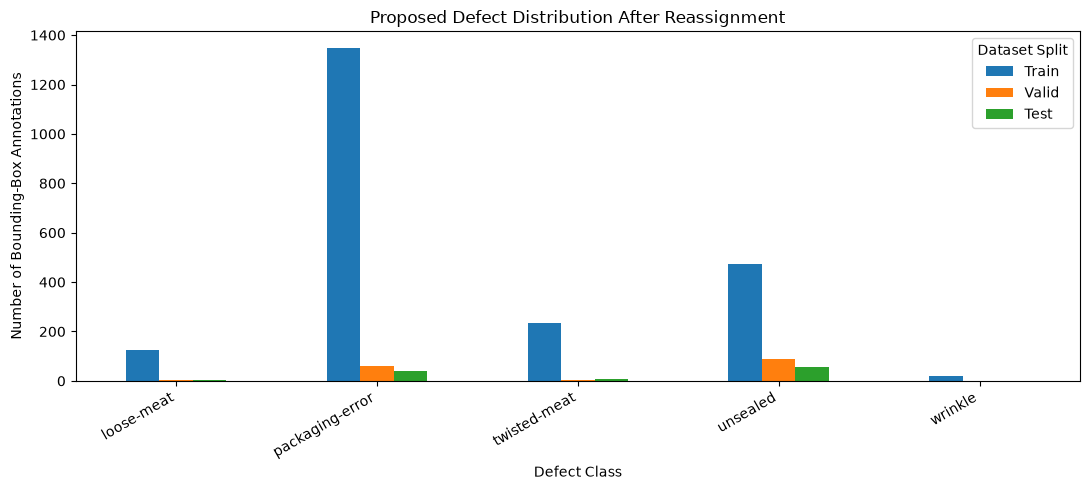

In [21]:
# plot proposed defect-class distribution

plot_df = distribution_df.set_index("Defect Class")[
    ["Train", "Valid", "Test"]
]

ax = plot_df.plot(
    kind="bar",
    figsize=(11, 5)
)

plt.title("Proposed Defect Distribution After Reassignment")
plt.xlabel("Defect Class")
plt.ylabel("Number of Bounding-Box Annotations")
plt.xticks(rotation=30, ha="right")
plt.legend(title="Dataset Split")
plt.tight_layout()
plt.show()

In [ ]:
# Identify original images containing wrinkle defects

wrinkle_category_id = 5

wrinkle_groups = {}

for split, dataset in datasets.items():

    images_by_id = {
        image["id"]: image
        for image in dataset["images"]
    }

    for ann in dataset["annotations"]:

        if ann["category_id"] != wrinkle_category_id:
            continue

        image = images_by_id[ann["image_id"]]

        original_name = image.get(
            "extra", {}
        ).get("name", image["file_name"])

        if original_name not in wrinkle_groups:
            wrinkle_groups[original_name] = {
                "Original Image": original_name,
                "Assigned Split": group_assignments[original_name],
                "Annotation Count": 0
            }

        wrinkle_groups[original_name]["Annotation Count"] += 1

wrinkle_df = pd.DataFrame(wrinkle_groups.values())

print("Total wrinkle annotations:",
      sum(row["Annotation Count"] for row in wrinkle_groups.values()))

print("Unique original images containing wrinkles:",
      len(wrinkle_groups))

display(wrinkle_df)

Total wrinkle annotations: 18
Unique original images containing wrinkles: 18


,Original Image,Assigned Split,Annotation Count
0,frame_with_red_10514.jpg,train,1
1,frame_with_red_9524.jpg,train,1
2,frame_with_red_10436.jpg,train,1
3,frame_with_red_10498.jpg,train,1
4,frame_with_red_10465.jpg,train,1
5,frame_with_red_10412.jpg,train,1
6,frame_with_red_10532.jpg,train,1
7,frame_with_red_10552.jpg,train,1
8,frame_with_red_5760.jpg,train,1
9,frame_with_red_10305.jpg,train,1


In [23]:
# count wrinkle-containing original images by split

if not wrinkle_df.empty:

    print("Wrinkle-containing original images by split:")

    print(
        wrinkle_df["Assigned Split"]
        .value_counts()
        .reindex(["train", "valid", "test"], fill_value=0)
    )

else:
    print("No wrinkle annotations found.")

Wrinkle-containing original images by split:
Assigned Split
train    18
valid     0
test      0
Name: count, dtype: int64


In [ ]:
# examine wrinkle-image frame numbers

def extract_frame_number(filename):
    """Extract the frame number from a source image filename.

    Args:
        filename (str): Filename containing 'frame_with_red_'.

    Returns:
        int or None: Extracted frame number, or None if not found.
    """
    match = re.search(r"frame_with_red_(\d+)", filename)
    return int(match.group(1)) if match else None


# Examine whether wrinkle annotations come from nearby video frames.
wrinkle_df["Frame Number"] = (
    wrinkle_df["Original Image"].apply(extract_frame_number)
)

wrinkle_sorted = wrinkle_df.sort_values("Frame Number")

display(
    wrinkle_sorted[
        ["Original Image", "Frame Number", "Assigned Split"]
    ]
)


,Original Image,Frame Number,Assigned Split
8,frame_with_red_5760.jpg,5760,train
12,frame_with_red_7808.jpg,7808,train
11,frame_with_red_8644.jpg,8644,train
1,frame_with_red_9524.jpg,9524,train
15,frame_with_red_10221.jpg,10221,train
16,frame_with_red_10262.jpg,10262,train
9,frame_with_red_10305.jpg,10305,train
13,frame_with_red_10369.jpg,10369,train
14,frame_with_red_10403.jpg,10403,train
5,frame_with_red_10412.jpg,10412,train


In [25]:
# examine gaps between wrinkle frame numbers

wrinkle_sorted = wrinkle_sorted.copy()

wrinkle_sorted["Frame Gap"] = (
    wrinkle_sorted["Frame Number"].diff()
)

display(
    wrinkle_sorted[
        ["Original Image", "Frame Number", "Frame Gap"]
    ]
)

,Original Image,Frame Number,Frame Gap
8,frame_with_red_5760.jpg,5760,NaN
12,frame_with_red_7808.jpg,7808,2048.0
11,frame_with_red_8644.jpg,8644,836.0
1,frame_with_red_9524.jpg,9524,880.0
15,frame_with_red_10221.jpg,10221,697.0
16,frame_with_red_10262.jpg,10262,41.0
9,frame_with_red_10305.jpg,10305,43.0
13,frame_with_red_10369.jpg,10369,64.0
14,frame_with_red_10403.jpg,10403,34.0
5,frame_with_red_10412.jpg,10412,9.0


In [ ]:
# Create separate output folders to preserve the original dataset.
PROCESSED_DIR = DATA_DIR / "processed"

for split in ["train", "valid", "test"]:
    (PROCESSED_DIR / split).mkdir(parents=True, exist_ok=True)

# Group annotations by image ID for efficient lookup.
annotations_by_image = {}

for split, dataset in datasets.items():
    grouped = defaultdict(list)

    for ann in dataset["annotations"]:
        grouped[ann["image_id"]].append(ann)

    annotations_by_image[split] = grouped

# Reconstruct each dataset split using the corrected assignments.
for target_split in ["train", "valid", "test"]:

    # Preserve COCO metadata while rebuilding image and annotation records.
    output = copy.deepcopy(datasets["train"])
    output["images"] = []
    output["annotations"] = []

    new_image_id = 0
    new_annotation_id = 1
    seen_originals = set()

    for source_split, dataset in datasets.items():
        for image in dataset["images"]:

            original_name = image.get(
                "extra", {}
            ).get("name", image["file_name"])

            if group_assignments[original_name] != target_split:
                continue

            # Keep one copy per original image in evaluation splits.
            if target_split != "train" and original_name in seen_originals:
                continue

            seen_originals.add(original_name)

            source_path = DATA_DIR / source_split / image["file_name"]

            # Prefix source split to distinguish exported filenames.
            new_filename = f"{source_split}_{image['file_name']}"
            destination = PROCESSED_DIR / target_split / new_filename

            shutil.copy2(source_path, destination)

            # Assign new IDs to maintain valid COCO image references.
            new_image = copy.deepcopy(image)
            new_image["id"] = new_image_id
            new_image["file_name"] = new_filename

            output["images"].append(new_image)

            for ann in annotations_by_image[source_split][image["id"]]:
                new_ann = copy.deepcopy(ann)
                new_ann["id"] = new_annotation_id
                new_ann["image_id"] = new_image_id

                output["annotations"].append(new_ann)
                new_annotation_id += 1

            new_image_id += 1

    # Save the reconstructed COCO annotations for each split.
    annotation_file = (
        PROCESSED_DIR / target_split / "_annotations.coco.json"
    )

    with annotation_file.open("w", encoding="utf-8") as file:
        json.dump(output, file, indent=2)

    print(
        f"{target_split}: "
        f"{len(output['images'])} images, "
        f"{len(output['annotations'])} annotations"
    )

print("\nProcessed dataset created successfully!")

train: 1741 images, 2201 annotations
valid: 114 images, 144 annotations
test: 76 images, 93 annotations

Processed dataset created successfully!


In [ ]:
# Reload the processed COCO annotations to verify saved outputs.
processed_datasets = {}

for split in ["train", "valid", "test"]:
    path = PROCESSED_DIR / split / "_annotations.coco.json"

    with path.open("r", encoding="utf-8") as file:
        processed_datasets[split] = json.load(file)

    dataset = processed_datasets[split]

    # Check that every image referenced in COCO exists on disk.
    missing_images = [
        img["file_name"]
        for img in dataset["images"]
        if not (PROCESSED_DIR / split / img["file_name"]).is_file()
    ]

    print(
        f"{split}: {len(dataset['images'])} images, "
        f"{len(dataset['annotations'])} annotations, "
        f"{len(missing_images)} missing files"
    )


def get_originals(dataset):
    """Return unique original image names from a COCO dataset.

    Args:
        dataset (dict): COCO dataset containing image metadata.

    Returns:
        set[str]: Unique original image filenames.
    """
    return {
        img.get("extra", {}).get("name", img["file_name"])
        for img in dataset["images"]
    }


# Verify that original images do not appear across multiple splits.
train_set = get_originals(processed_datasets["train"])
valid_set = get_originals(processed_datasets["valid"])
test_set = get_originals(processed_datasets["test"])

print("\nCross-split overlaps:")
print("Train / Valid:", len(train_set & valid_set))
print("Train / Test:", len(train_set & test_set))
print("Valid / Test:", len(valid_set & test_set))


train: 1741 images, 2201 annotations, 0 missing files
valid: 114 images, 144 annotations, 0 missing files
test: 76 images, 93 annotations, 0 missing files

Cross-split overlaps:
Train / Valid: 0
Train / Test: 0
Valid / Test: 0


In [ ]:
# Verify annotation references and bounding-box geometry.
for split, dataset in processed_datasets.items():

    # Map image IDs and category IDs for validation.
    images = {
        img["id"]: img
        for img in dataset["images"]
    }

    category_ids = {
        cat["id"]
        for cat in dataset["categories"]
    }

    invalid = []

    for ann in dataset["annotations"]:
        image = images.get(ann["image_id"])

        # Reject annotations with missing images or unknown categories.
        if image is None or ann["category_id"] not in category_ids:
            invalid.append(ann["id"])
            continue

        # COCO boxes use [x_min, y_min, width, height].
        x, y, w, h = ann["bbox"]

        # Ensure boxes have positive dimensions and fit within the image.
        # A small tolerance accounts for floating-point rounding.
        if (
            w <= 0
            or h <= 0
            or x < 0
            or y < 0
            or x + w > image["width"] + 1e-6
            or y + h > image["height"] + 1e-6
        ):
            invalid.append(ann["id"])

    print(f"{split}: {len(invalid)} invalid annotations")


train: 0 invalid annotations
valid: 0 invalid annotations
test: 0 invalid annotations
